In [1]:
"""
Imports required libraries for model inference, image processing,
and post-processing of the predicted segmentation mask.
"""
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import remove_small_objects
from skimage.measure import label, regionprops
from tensorflow.keras.models import load_model

2026-01-08 14:04:28.198554: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
def f1(y_true, y_pred):
    def recall_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Positives = K.sum(K.round(K.clip(y_true, 0, 1)))
        recall = TP / (Positives+K.epsilon())
        return recall
    
    def precision_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Pred_Positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
        precision = TP / (Pred_Positives+K.epsilon())
        return precision
    
    precision, recall = precision_m(y_true, y_pred), recall_m(y_true, y_pred)
    
    return 2*((precision*recall)/(precision+recall+K.epsilon()))

In [3]:
# Load the model you trained in task5_training.ipynb
patch_size = 192  
example_file_name = 'ahmed_245226_unet_model_192px.h5'
model = load_model(example_file_name, custom_objects={"f1": f1}, compile=False)
print("Model loaded successfully!")


2026-01-08 14:04:32.552342: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1767881072.553670   25715 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 42361 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:c1:00.0, compute capability: 8.6


Model loaded successfully!


Original size: 3006 4112


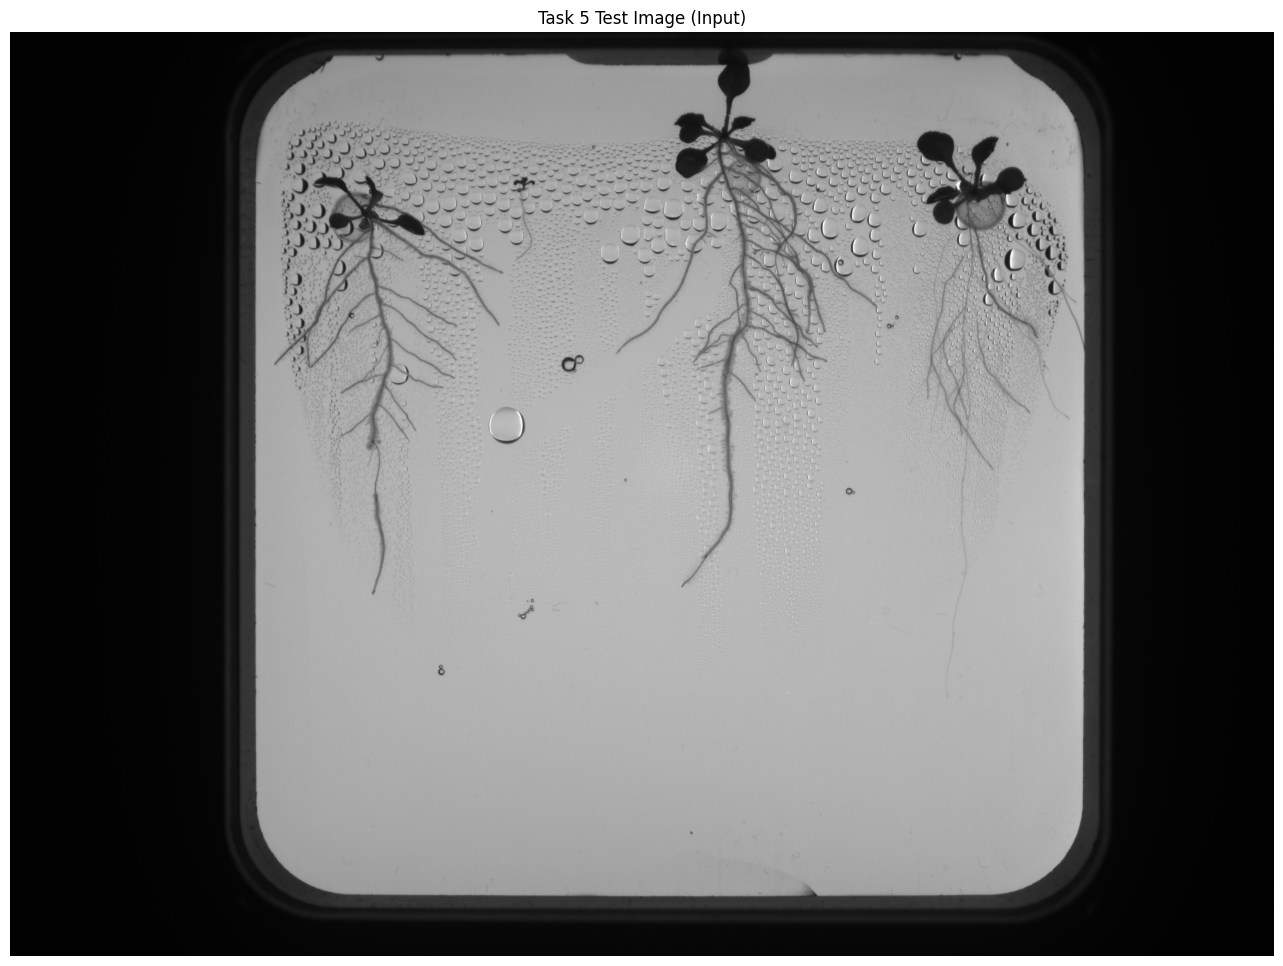

In [4]:
"""
Loads the Task 5 test image in grayscale, prints its original size,
and displays the image for visual confirmation before inference.
"""
# Load the test image
task5_test_image_path = 'task5_test_image.png'
image = cv2.imread(task5_test_image_path, cv2.IMREAD_GRAYSCALE)
# Get and print image dimensions
orig_h, orig_w = image.shape
print("Original size:", orig_h, orig_w)
# Show the image
plt.figure(figsize=(22, 12))
plt.imshow(image, cmap='gray')
plt.title("Task 5 Test Image (Input)")
plt.axis("off")
plt.show()


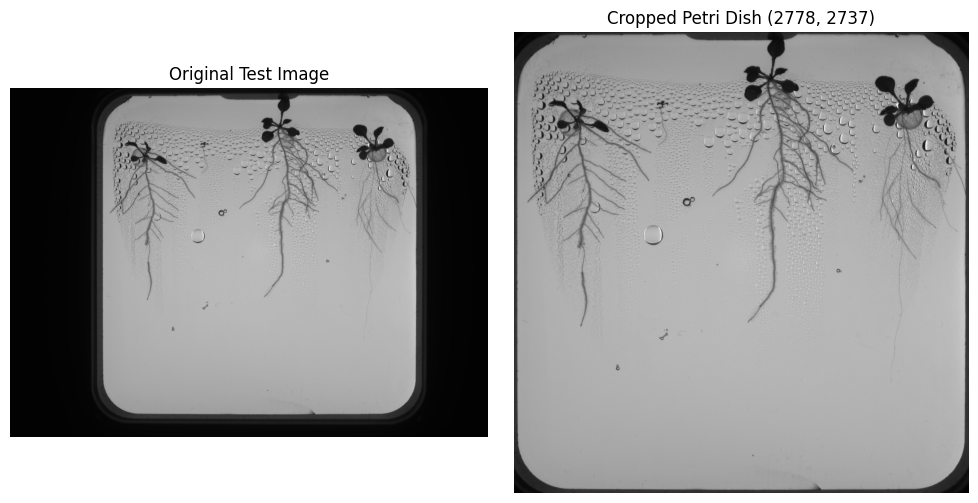

In [5]:
"""
Crops the Petri dish area from the input image to remove useless background.
Then shows a before/after comparison so we can visually confirm the crop is correct.
"""
MARGIN_PX = 18

def crop_petri_dish(img):

    H, W = img.shape

    blur = cv2.GaussianBlur(img, (9, 9), 0)
    _, thresh = cv2.threshold(
        blur, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    bright = (thresh == 255)
    bright = remove_small_objects(bright, min_size=5000)

    labeled = label(bright)
    regions = regionprops(labeled)

    if not regions:
        size = min(H, W)
        sy = (H - size) // 2
        sx = (W - size) // 2
        cropped = img[sy:sy+size, sx:sx+size]
        crop_coords = (sy, sx, sy + size, sx + size)
        return cropped, crop_coords

    r = max(regions, key=lambda r: r.area)
    minr, minc, maxr, maxc = r.bbox

    minr2 = max(minr - MARGIN_PX, 0)
    minc2 = max(minc - MARGIN_PX, 0)
    maxr2 = min(maxr + MARGIN_PX, H)
    maxc2 = min(maxc + MARGIN_PX, W)

    cropped = img[minr2:maxr2, minc2:maxc2]
    crop_coords = (minr2, minc2, maxr2, maxc2)
    return cropped, crop_coords


def visualize_before_after(original, cropped):
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(original, cmap="gray")
    plt.title("Original Test Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(cropped, cmap="gray")
    plt.title(f"Cropped Petri Dish {cropped.shape}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


#  RUN (image is already loaded by you) 
cropped_image, crop_coords = crop_petri_dish(image)
visualize_before_after(image, cropped_image)

In [6]:
# Find the petri dish
cropped_image.shape

(2778, 2737)

In [7]:
"""
Pads the cropped Petri dish image so its height and width are divisible by patch_size.
This makes patch-based prediction possible without leftover edges.
"""
def pad_to_multiple_center(img, patch_size=192):
    h, w = img.shape

    new_h = ((h - 1) // patch_size + 1) * patch_size
    new_w = ((w - 1) // patch_size + 1) * patch_size

    pad_top  = (new_h - h) // 2
    pad_left = (new_w - w) // 2
    pad_bot  = new_h - h - pad_top
    pad_right = new_w - w - pad_left

    padded = np.pad(
        img,
        ((pad_top, pad_bot), (pad_left, pad_right)),
        mode="constant",
        constant_values=0
    )
    return padded, (pad_top, pad_left), (h, w)

# Centered padding
petri_dish_padded, pad_offsets, crop_hw = pad_to_multiple_center(cropped_image, patch_size=patch_size)

print("Cropped shape:", cropped_image.shape)
print("Padded shape :", petri_dish_padded.shape)
print("Pad offsets  :", pad_offsets)



Cropped shape: (2778, 2737)
Padded shape : (2880, 2880)
Pad offsets  : (51, 71)


Total patches: 225


2026-01-08 14:04:49.341732: I external/local_xla/xla/service/service.cc:163] XLA service 0x7f29c000c3c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-01-08 14:04:49.341761: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA RTX A6000, Compute Capability 8.6
2026-01-08 14:04:49.363988: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-01-08 14:04:49.462207: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 90701


6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step

I0000 00:00:1767881093.915343   26490 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 210ms/step


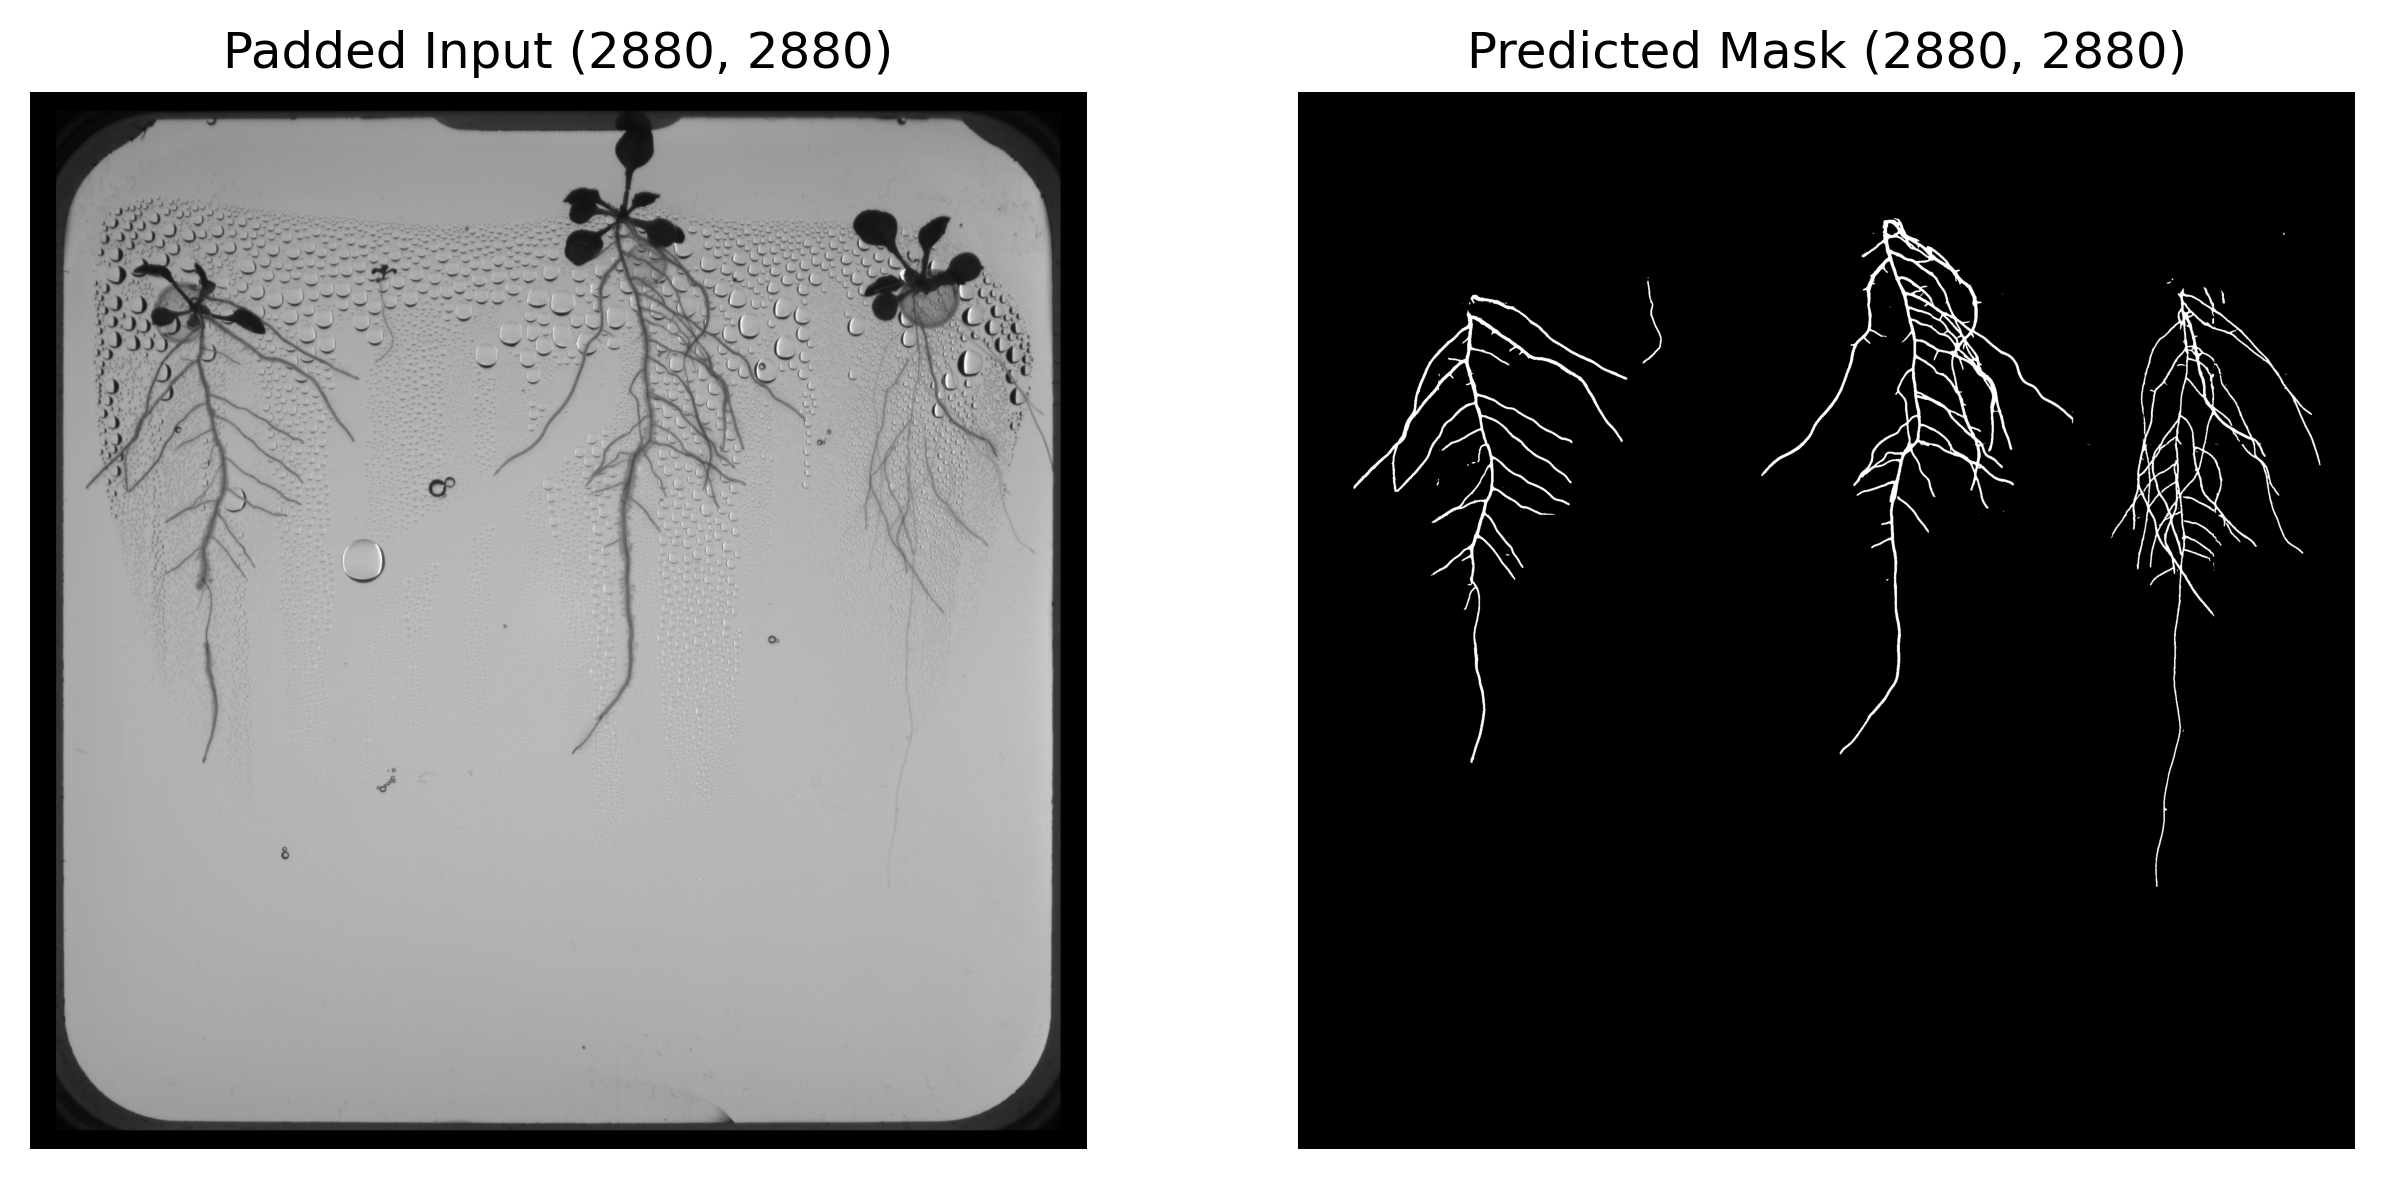

In [8]:
"""
Splits the padded Petri dish image into 192x192 patches, runs the model on each patch,
reconstructs the full predicted mask, thresholds it to a binary mask, and displays the result.
"""

# 1) PATCH THE IMAGE
def patchify_image(img, patch_size=192):
    patches = []
    h, w = img.shape
    for i in range(0, h, patch_size):
        for j in range(0, w, patch_size):
            patches.append(img[i:i+patch_size, j:j+patch_size])
    return np.array(patches)

patches = patchify_image(petri_dish_padded, patch_size=patch_size)

# Prepare for U-Net (add channel dim + normalize)
patches_input = patches.reshape(-1, patch_size, patch_size, 1).astype("float32") / 255.0
print("Total patches:", len(patches_input))

# 2) PREDICT MASK PATCHES
preds = model.predict(patches_input).squeeze()

# 3) UNPATCH (RECONSTRUCT FULL MASK)
def unpatchify(patches, full_h, full_w, patch_size=192):
    reconstructed = np.zeros((full_h, full_w), dtype=np.float32)
    idx = 0
    for i in range(0, full_h, patch_size):
        for j in range(0, full_w, patch_size):
            reconstructed[i:i+patch_size, j:j+patch_size] = patches[idx]
            idx += 1
    return reconstructed

# Reconstruct full mask (on the padded canvas)
predicted_mask = unpatchify(preds, *petri_dish_padded.shape, patch_size=patch_size)
predicted_mask = (predicted_mask > 0.5).astype(np.uint8)

# Visualize padded input and predicted mask
f, ax = plt.subplots(1, 2, dpi=300, figsize=(10, 5))

ax[0].imshow(petri_dish_padded, cmap="gray")
ax[0].axis("off")
ax[0].set_title(f"Padded Input {petri_dish_padded.shape}")

ax[1].imshow(predicted_mask, cmap="gray")
ax[1].axis("off")
ax[1].set_title(f"Predicted Mask {predicted_mask.shape}")

plt.show()

In [9]:
predicted_mask.shape, image.shape

((2880, 2880), (3006, 4112))

As you can see `predicted_mask` and `image` have different shapes. This is because of cropping and padding.

**REQUIREMENT:** The input and output should have the same size and should be aligned perfectly. To achieve this, you need to reverse the effects of cropping and padding added during processing. This will ensure the final mask aligns with the original image.

In [10]:
"""
Removes the centered padding from the predicted mask, then places the cropped mask back into the
original image size so the final output aligns with the raw input image.
"""

(minr, minc, maxr, maxc) = crop_coords
crop_h = maxr - minr
crop_w = maxc - minc

(pad_top, pad_left) = pad_offsets  # from pad_to_multiple_center()

# Remove padding (centered)
uncropped_mask = predicted_mask[pad_top:pad_top+crop_h, pad_left:pad_left+crop_w]
print("After removing padding:", uncropped_mask.shape)

# Place back into original image coordinates
predicted_mask_corrected = np.zeros((orig_h, orig_w), dtype=np.uint8)
predicted_mask_corrected[minr:maxr, minc:maxc] = uncropped_mask
print("FINAL corrected mask shape:", predicted_mask_corrected.shape)


After removing padding: (2778, 2737)
FINAL corrected mask shape: (3006, 4112)


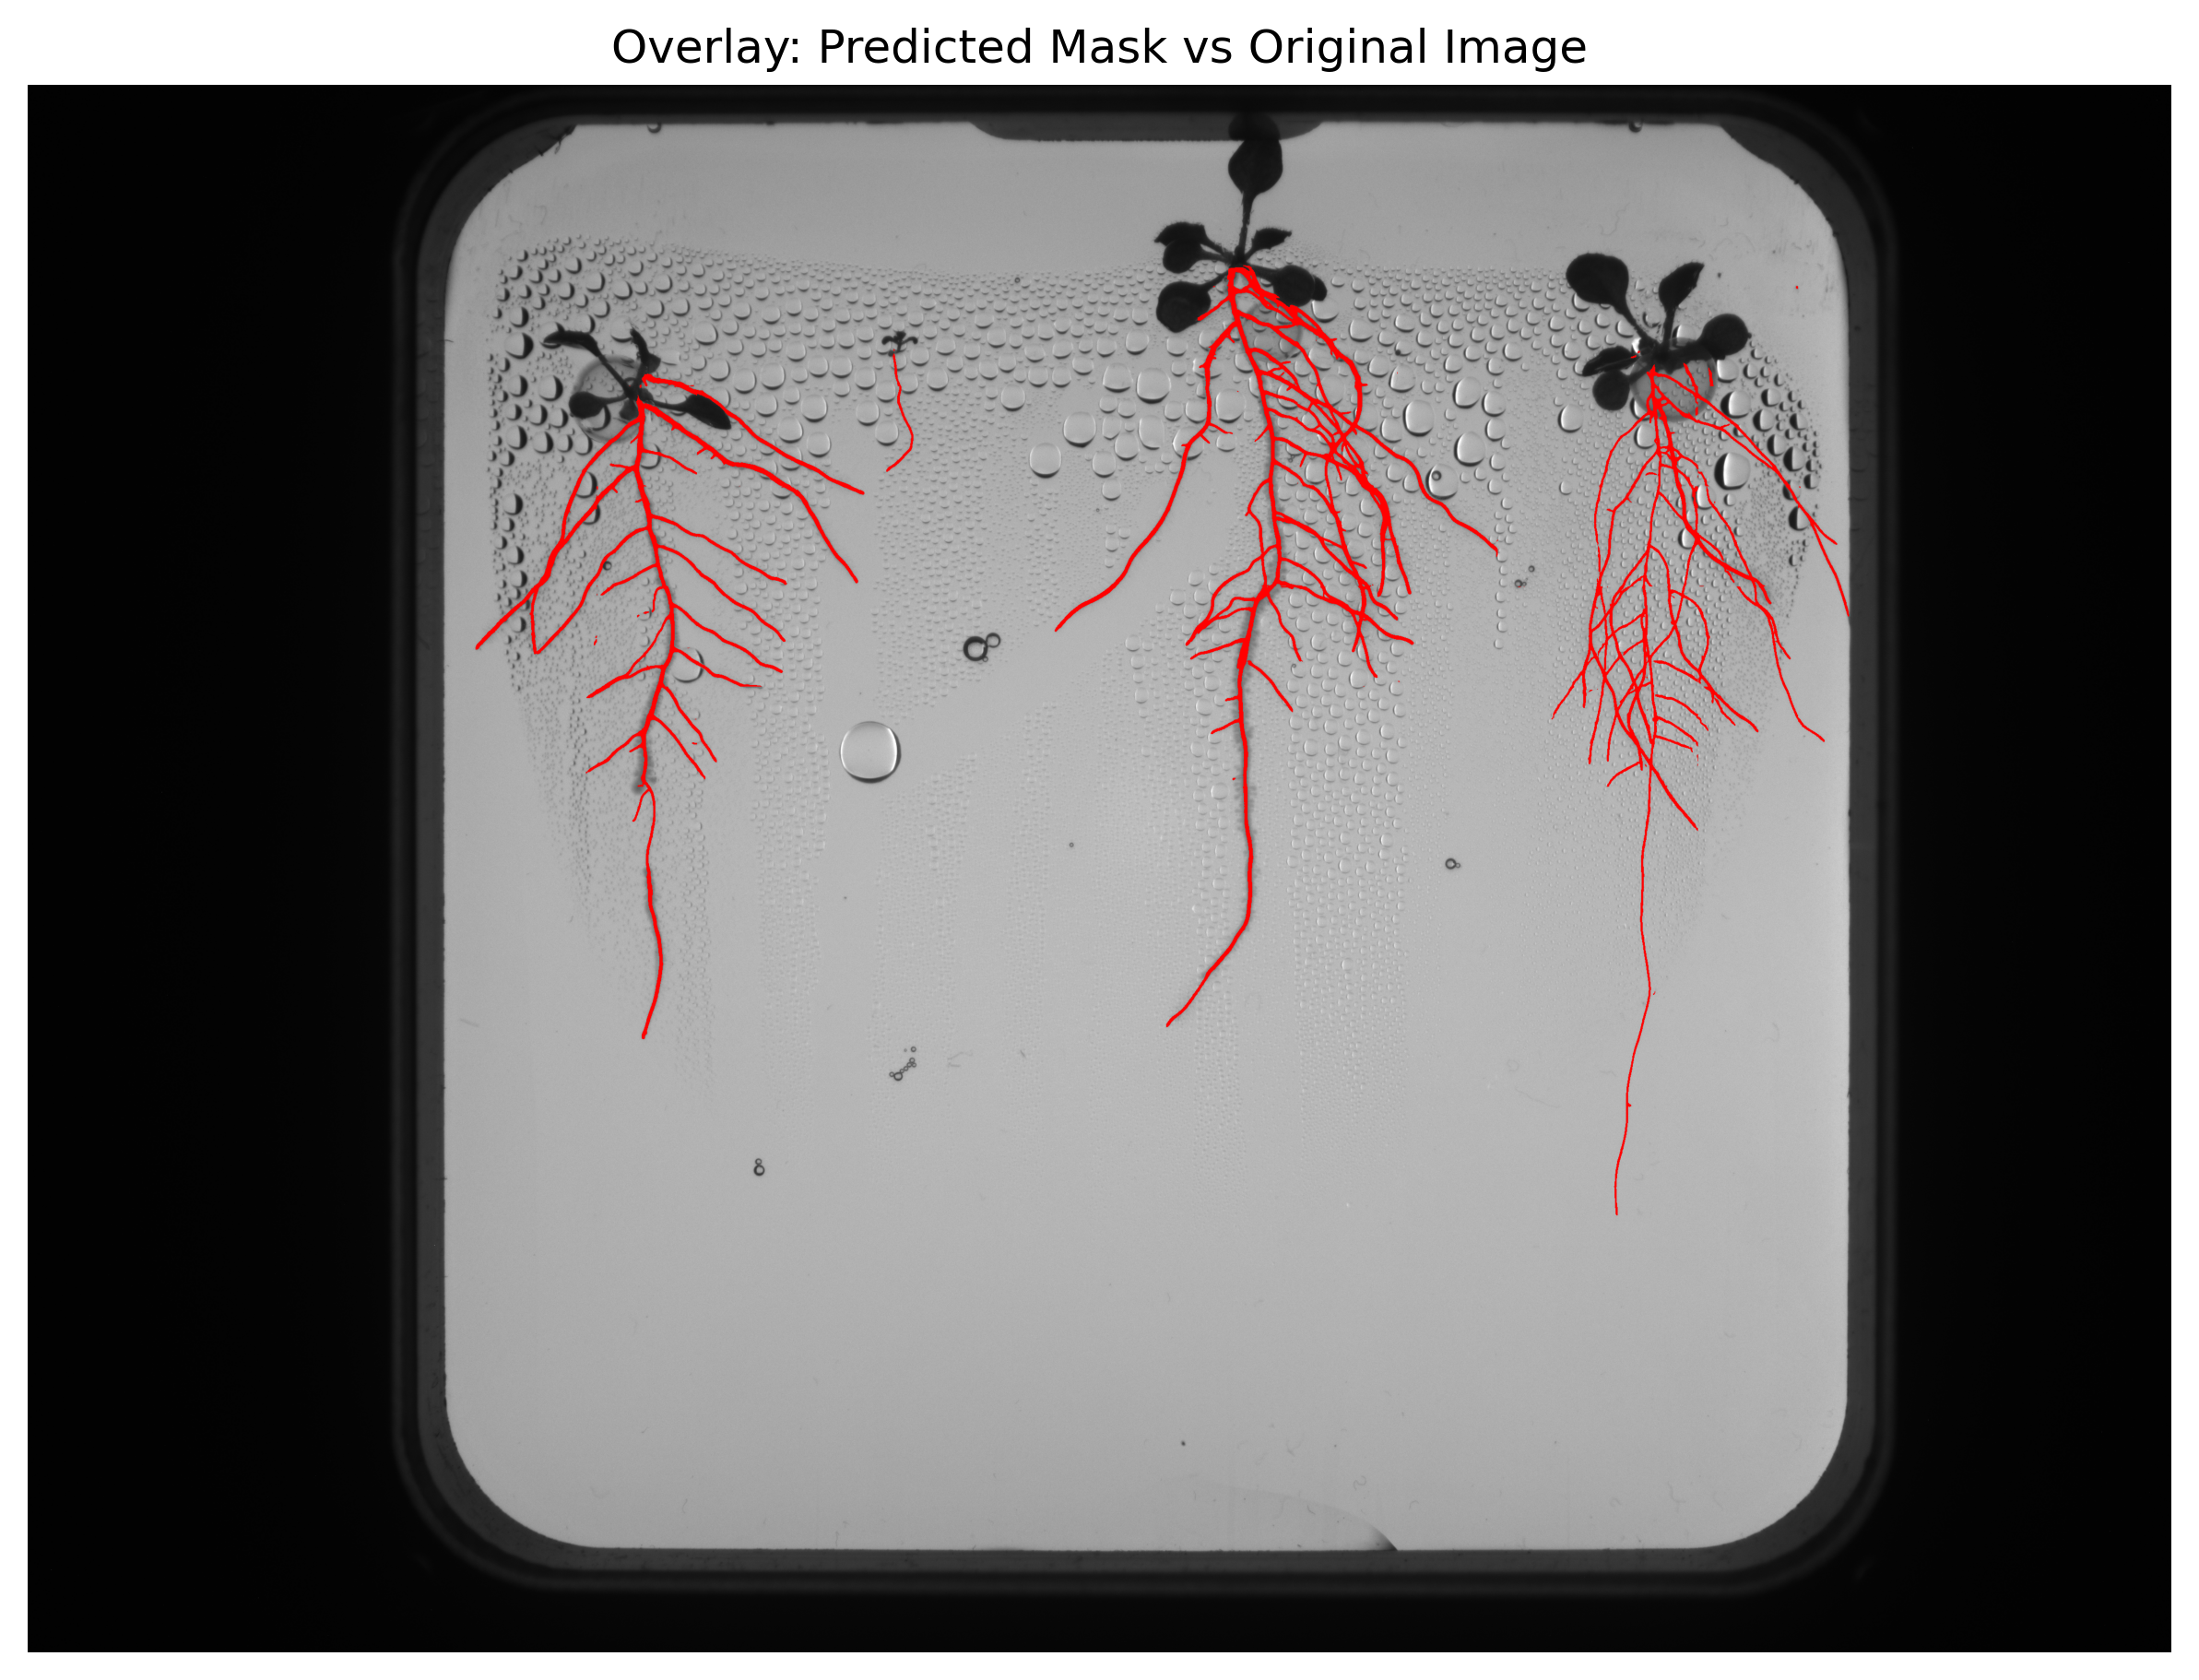

In [11]:
# REQUIREMENT: Predicted roots must align with the original image.
# REQUIREMENT: Plot such an image to prove alignment.

# Make sure both are uint8
orig_vis = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
mask_vis = (predicted_mask_corrected * 255).astype(np.uint8)

# Create a red overlay (root pixels = red)
overlay_image = orig_vis.copy()
overlay_image[mask_vis == 255] = [255, 0, 0]   
plt.figure(figsize=(10,10), dpi=300)
plt.imshow(overlay_image)
plt.title("Overlay: Predicted Mask vs Original Image")
plt.axis("off")
plt.show()



In [12]:
# REQUIREMENT: Save the predicted mask, it is a deliverable.
# REQUIREMENT: Input/Output size must be the same.
# REQUIREMENT: Predicted roots must align with the original image.
# REQUIREMENT: The predicted mask must be binary.
# REQUIREMENT: Non-root pixels must be 0, root pixels must be 255 (unlike Task 1)
# REQUIREMENT: naming convention task5_test_image_prediction_studentname_studentnumber.png
mask_image = (predicted_mask_corrected * 255).astype(np.uint8)
assert predicted_mask_corrected.shape == image.shape
cv2.imwrite('task5_test_image_prediction_ahmed_245226.png', mask_image)
print("Saved:", 'task5_test_image_prediction_ahmed_245226.png')


Saved: task5_test_image_prediction_ahmed_245226.png


Note: I have trained the model on the Y2B_23 dataset, since there are no labels for Y2B_24 dataset yet. The test image is from Y2B_24, this is why the predicted mask is suboptimal. Therefore do not take the performance of this prediction as a reference. Your predictions should be much better than this.